# GridLeak AI — Açıklanabilirlik ve Sonuçlar

Mevcut master defterin hücreleri içerikleri ve kayıtlı çıktıları korunarak bu deftere taşınmıştır. Ortak hazırlık hücreleri bağımsız açılış için tekrar yer alır.

Bu düzenleme yeni eğitim veya değerlendirme çalıştırmamıştır. Hücreleri çalıştırmak ilgili hesaplamaları yeniden yürütür.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, average_precision_score, roc_auc_score, f1_score,
    precision_score, recall_score, precision_recall_curve, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay
)
warnings.filterwarnings('ignore')

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ai/features/v3_features.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Projedeki GERÇEK üretim modüllerini doğrudan içe aktarıyoruz (sıfır kod tekrarı!)
from ai.features.v3_features import load_raw_for_ids, extract_subscriber_features, FoldContextTransformer
from ai.training.v3_final_train_and_test import build_base_estimators, build_meta_estimator, ece_score

EXP = ROOT / 'ai/artifacts/iyilestirme_v3_20261123T171349Z'
V3 = ROOT / 'data/processed/v3'
lock = json.loads((EXP / 'locked_selection.json').read_text(encoding='utf-8'))
fcols = lock['features']
print('Proje Kökü:', ROOT)
print('Aktif Kilitli Model:', lock['model_name'])
print('Kilitli Özellik Sayısı:', len(fcols))

Proje Kökü: c:\Users\kadir\GridLeakAI
Aktif Kilitli Model: Calibrated Stacking v3 (LGBM + CatBoost + XGBoost + MLP)
Kilitli Özellik Sayısı: 160


## 1. Veri Seti Yapısı, %80/%20 Abone Bölünmesi ve Sınıf Dengesizliği
Aboneler kimlik (`CONS_NO`) bazında tabakalı bölünmüştür; eğitim ve test arasında **sıfır ortak abone** vardır.

In [2]:
train_df = pd.read_csv(V3 / 'egitim_ozellikleri_2016_v1.csv', dtype={'CONS_NO': str})
test_df = pd.read_csv(V3 / 'test_ozellikleri_2016_v1.csv', dtype={'CONS_NO': str})
test_y_df = pd.read_csv(V3 / 'test_hedefleri_2016_v1.csv', dtype={'CONS_NO': str}).set_index('CONS_NO')
assert not (set(train_df['CONS_NO']) & set(test_df['CONS_NO'])), 'Eğitim/Test sızıntısı!'

y_tr = train_df['FLAG'].to_numpy(int)
y_te = test_y_df.loc[test_df['CONS_NO'], 'FLAG'].to_numpy(int)
print(f'Eğitim: {len(train_df):,} abone | FLAG=0: {(y_tr==0).sum():,} (%{(y_tr==0).mean()*100:.2f}) | FLAG=1: {(y_tr==1).sum():,} (%{y_tr.mean()*100:.2f})')
print(f'Test  : {len(test_df):,} abone | FLAG=0: {(y_te==0).sum():,} (%{(y_te==0).mean()*100:.2f}) | FLAG=1: {(y_te==1).sum():,} (%{y_te.mean()*100:.2f})')
print('Eğitim-Test Ortak Abone Sayısı: 0')

Eğitim: 33,858 abone | FLAG=0: 30,996 (%91.55) | FLAG=1: 2,862 (%8.45)
Test  : 8,466 abone | FLAG=0: 7,748 (%91.52) | FLAG=1: 718 (%8.48)
Eğitim-Test Ortak Abone Sayısı: 0


## 4. 4 Aileli Kalibre Stacking Mimarisi ve Bağımsız 5-Fold OOF Sonuçları
Eğitilmiş final modeli (`ensemble_v3.joblib`) inceleyerek içindeki 4 farklı aileyi (**LightGBM, CatBoost, XGBoost, RankGauss MLP**) ve logit-uzayı Sigmoid/Platt meta-öğrenicisini doğruluyoruz.

In [5]:
model = joblib.load(EXP / 'ensemble_v3.joblib')
print('Temel Model Aileleri:', list(model.named_estimators_.keys()))
print('Meta-Öğrenici (Kalibrasyon):', model.final_estimator_)
print('decision_function var mı? (False olmalı):', hasattr(model, 'decision_function'))

cv_df = pd.read_csv(EXP / 'model_karsilastirma.csv')
display(cv_df)

Temel Model Aileleri: ['lgbm', 'catboost', 'xgboost', 'mlp']
Meta-Öğrenici (Kalibrasyon): Pipeline(steps=[('clip',
                 FunctionTransformer(func=<function clip at 0x0000020B4E60BDF0>,
                                     kw_args={'a_max': 0.999999,
                                              'a_min': 1e-06})),
                ('logit', FunctionTransformer(func=<ufunc 'logit'>)),
                ('cal',
                 CalibratedClassifierCV(cv=3,
                                        estimator=LogisticRegression(C=0.5,
                                                                     max_iter=1000)))])
decision_function var mı? (False olmalı): False


,Model,CV_Folds,OOF_AP,OOF_ROC_AUC,OOF_F1,OOF_Precision,OOF_Recall,OOF_FP,OOF_FN
0,lgbm,5,0.63275,0.90780,0.5801,0.6182,0.5465,966,1298
1,catboost,5,0.62082,0.90091,0.5738,0.6041,0.5465,1025,1298
2,xgboost,5,0.61942,0.90413,0.5632,0.5915,0.5374,1062,1324
3,mlp,5,0.50656,0.84909,0.4845,0.4803,0.4888,1514,1463
4,Calibrated Stacking v3 (LGBM + CatBoost + XGBo...,5,0.63565,0.90847,0.5775,0.6068,0.5510,1022,1285


## 5. Açıklanabilir Yapay Zeka — Canlı LightGBM TreeSHAP
Final ensemble içindeki ana bileşen `model.named_estimators_['lgbm']` üzerinden en yüksek riskli abonenin canlı TreeSHAP katkılarını doğruluyor ve ilk 2.000 yüksek riskli abonenin küresel önem grafiğini çiziyoruz.

Canlı TreeSHAP matrisi: (5, 160) (5 abone × 160 özellik), temel değer: -4.794


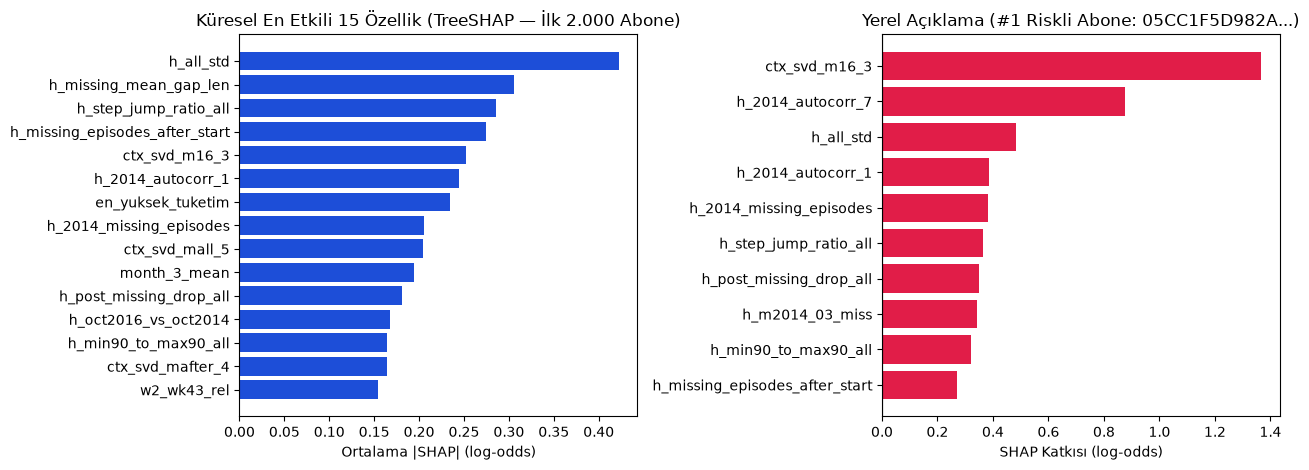

In [6]:
shap_dir = sorted(EXP.glob('shap_*'))[-1]
g_shap = pd.read_csv(shap_dir / 'genel_ozellik_onemi.csv')
l_shap = pd.read_csv(shap_dir / 'yerel_katkilar.csv')
s_info = json.loads((shap_dir / 'aciklama_bilgisi.json').read_text(encoding='utf-8'))

# Canlı TreeSHAP doğrulaması (ilk 5 test abonesi)
live_contrib = model.named_estimators_['lgbm'].booster_.predict(test_df[fcols].head(5), pred_contrib=True)
print(f'Canlı TreeSHAP matrisi: {live_contrib[:, :-1].shape} (5 abone × 160 özellik), temel değer: {live_contrib[0, -1]:.3f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
top15 = g_shap.head(15).iloc[::-1]
ax1.barh(top15['ozellik'], top15['ortalama_mutlak_shap'], color='#1D4ED8')
ax1.set_title('Küresel En Etkili 15 Özellik (TreeSHAP — İlk 2.000 Abone)')
ax1.set_xlabel('Ortalama |SHAP| (log-odds)')

loc10 = l_shap.head(10).iloc[::-1]
ax2.barh(loc10['ozellik'], loc10['shap_katkisi'], color=['#E11D48' if v>0 else '#0D9488' for v in loc10['shap_katkisi']])
ax2.axvline(0, color='black', lw=0.8)
ax2.set_title(f"Yerel Açıklama (#1 Riskli Abone: {s_info['yerel_abone'][:12]}...)")
ax2.set_xlabel('SHAP Katkısı (log-odds)')
plt.tight_layout(); plt.show()